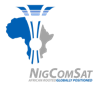 &nbsp;&nbsp; 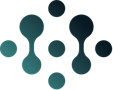

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/jasons-restructure/Jasons-Restructure/week-2/day-3-lab-day-quiz-1-and-project-kickoff/4-instructor-only/W2D3-solution.ipynb)

> 🧑🏾‍🏫 **INSTRUCTOR SOLUTION.** Every blank is filled in. Don't share this with participants before the session ends.

# 🔬 Week 2 · Day 3: Mini Investigation, *Is our battery getting tired?* 🔋

**The story:** you've just joined the power-subsystem desk. Your oga asks two questions:
1. *Is the battery ageing?*
2. *Does anything about it repeat, and how often?*

You have **three years of daily battery data** and **everything you learned in Weeks 1–2**. Less hand-holding today: you drive. 🚗

| Symbol | Means |
|---|---|
| ▶️ | Run the cell (**Shift + Enter**) |
| ✍️ | Your turn: replace every `___` |
| ✅ / ❌ | The check marks it, with a hint if needed |
| 🌶️ | Bonus for fast finishers |

> ## ⚠️ First: **File → Save a copy in Drive**

**Help:** `W2D3-rulebook.pdf`, plus your rule books and glossaries from Days 1–5.

## ▶️ STEP 0: Set up
Run it and wait for `✅ Ready!`. (After any restart, run it again.)

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _bat(week="week-03"):
    return pd.read_csv(data_path("battery_health_daily", week=week), parse_dates=["date"], index_col="date").asfreq("D")

_MONTHS = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
def _month_no(x):
    s = str(x).strip().lower()
    if s.isdigit():
        return int(s)
    return _MONTHS.index(s[:3]) + 1

def _c_l1(x):
    want = ("week-03", "date", "D")
    got = tuple(str(v).strip() for v in x)
    wrong = [n for n, g, w in zip(["WEEK", "TIME_COL", "FREQ"], got, want) if g != w]
    return not wrong, "Right file, right time column, right rhythm. The clean week-03 version is loaded. 🔋", \
        f"Check {wrong}. Week folder looks like \"week-03\", the time column is in head(), daily is \"D\"."

def _c_l2(x):
    b = _bat()
    want = (len(b), int(b.isna().sum().sum()), int(b.index.duplicated().sum()))
    return tuple(int(v) for v in x) == want, f"{want[0]:,} days, {want[1]} empty cells, {want[2]} duplicates. Clean data: rare in real life, enjoy it! 😄", \
        "len(bat), bat.isna().sum().sum(), bat.index.duplicated().sum()"

def _c_l3(x):
    b = _bat()
    want = b.index[b["est_capacity_ah"] < 97][0]
    return pd.Timestamp(x) == want, f"{want.date()}: right inside the September eclipse season. The battery works hardest then. 🌗", \
        "bat.index[bat[\"est_capacity_ah\"] < PRACTICE_LINE][0] gives the first date under the line."

def _c_l4(x):
    return isinstance(x, str) and len(x.strip()) >= 15 and x.strip().lower() not in {"capacity", "battery", "est_capacity_ah"}, \
        "A title with a finding. Your oga can read the answer without reading the chart. 👌🏾", \
        "Write a sentence (at least 15 characters) that says what the chart SHOWS."

def _c_l5(x):
    w = int(x)
    ok = 175 <= w <= 190 or 355 <= w <= 370
    return ok, f"{w} days swallows the eclipse pattern ({'half a year: one season to the next' if w < 300 else 'a full year: both seasons'}).", \
        "Eclipse seasons come about half a year apart. Pick a window of about half a year or a full year, in days."

def _c_l6(x):
    w = int(globals().get("WINDOW") or 365)
    r = _bat()["eod_voltage_v"].rolling(w).mean()
    want = round(float(r.dropna().iloc[0] - r.iloc[-1]), 3)
    return abs(float(x) - want) < 0.002, f"The smoothed voltage fell {want:.3f} V: that's the ageing, with the eclipse noise removed.", \
        "smooth.dropna().iloc[0] - smooth.iloc[-1]  (first full value minus the last value)"

def _c_l7(x):
    p = int(x)
    msg = {12: "12 = one calendar year. 36 months = 3 full cycles, the minimum to trust it.",
           6: "6 = half a year, one eclipse season to the next. The process justifies it!"}
    return p in msg, msg.get(p, ""), "Monthly data with a calendar-year pattern. How many months in a year? (Half a year also works.)"

def _c_l8(x):
    got = {_month_no(v) for v in x}
    return got == {3, 9}, "March and September: the equinoxes, when Earth's shadow crosses the orbit. Two eclipse seasons a year! 🌍🌗", \
        "Look at the seasonal bar chart: which TWO months stick up the most?"

def _c_l9(x):
    from statsmodels.tsa.stattools import acf
    m = _bat()["depth_of_discharge_pct"].resample("MS").mean()
    a = acf(m, nlags=18)
    want = int(np.argmax(a[2:]) + 2)
    return int(x) == want, f"Lag {want}: the pattern repeats every {want} months, twice a year. The correlogram confirmed the process. 🎯", \
        "Ignore lag 0 and lag 1. Which bar after that is the tallest?"

def _c_l10(x):
    parts = [str(v).strip() for v in x]
    short = [n for n, p in zip(["situation", "observation", "implication", "recommendation"], parts) if len(p) < 25]
    has_num = any(ch.isdigit() for ch in parts[1])
    ok = not short and has_num
    hint = (f"Make these longer (25+ characters each): {short}. " if short else "") + ("" if has_num else "Your OBSERVATION needs a number.")
    return ok, "Four solid sentences. That's the format your final-project report uses. 📝", hint

def _c_bonus(x):
    a, b = _bat("week-03"), _bat("week-04")
    d = (a["est_capacity_ah"] - b["est_capacity_ah"]).abs()
    want = d[d > 1e-9].index[0]
    return pd.Timestamp(x) == want, f"{want.date()}: from there the week-04 file fades faster (the planted fault for Week 3). Same name, different data! 🕵🏾", \
        "Subtract the two capacity columns, keep the rows where the difference isn't zero, take the first date."

CHECKS = {"L1": _c_l1, "L2": _c_l2, "L3": _c_l3, "L4": _c_l4, "L5": _c_l5, "L6": _c_l6, "L7": _c_l7,
          "L8": _c_l8, "L9": _c_l9, "L10": _c_l10, "BONUS": _c_bonus}
HINTS = {"L3": "Give a date, e.g. bat.index[...][0]", "L8": "Give two month names, e.g. (\"Jan\", \"Feb\")"}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


---
# 1 · Load and profile (10 min) 📥

⚠️ **The trap:** `battery_health_daily.csv` exists in **two** original folders. `week-03` is the clean version. `week-04` has faults planted on purpose for Week 3 of our course.
Today you want the **clean** one.

### L1 ✍️ Three settings
- `WEEK`: which folder? (`"week-03"` or `"week-04"`)
- `TIME_COL`: the name of the time column (peek at the CSV: it's a date per row)
- `FREQ`: the rhythm code for **daily**

In [ ]:
WEEK = "week-03"
TIME_COL = "date"
FREQ = "D"

check("L1", (WEEK, TIME_COL, FREQ))

In [ ]:
assert None not in (WEEK, TIME_COL, FREQ), "✍️ Do L1 first: fill in all three settings, then run this cell again."

bat = pd.read_csv(data_path("battery_health_daily", week=WEEK),
                  parse_dates=[TIME_COL], index_col=TIME_COL).asfreq(FREQ)
bat.head()

| Column | In plain words |
|---|---|
| `eclipse_minutes` | how long the satellite sat in Earth's shadow that day (running on battery, like your inverter when NEPA takes light) |
| `depth_of_discharge_pct` | how far the battery was drained that day (%) |
| `eod_voltage_v` | battery voltage at the end of the drain (volts) |
| `est_capacity_ah` | how much charge the battery can still hold (amp-hours). **This is the “tiredness” number.** |
| `cycle_count` | total charge/discharge cycles so far |

### L2 ✍️ Profile it: the tokunbo-car inspection 🚗🔍
Three numbers: how many **rows**, how many **empty cells** in the whole table, how many **duplicate timestamps**.

In [ ]:
n_rows = len(bat)
n_missing = bat.isna().sum().sum()
n_dups = bat.index.duplicated().sum()

check("L2", (n_rows, n_missing, n_dups))

---
# 2 · An honest plot (10 min) 📈

Real limits come from the spacecraft engineers. For practice we use a **made-up alert line: 97 Ah**.

### L3 ✍️ When did capacity FIRST drop below the line?
Hint: filter the index where the capacity is below the line, then take the first one: `[0]`.

In [ ]:
PRACTICE_LINE = 97   # amp-hours, made up for practice

first_below = bat.index[bat["est_capacity_ah"] < PRACTICE_LINE][0]

check("L3", first_below)

### L4 ✍️ Draw it with the line on the chart, and a title that states the finding
Run it once to look, then write your title sentence.

In [ ]:
my_title = "Battery capacity fades steadily and first dips below the 97 Ah practice line in late 2025"

bat["est_capacity_ah"].plot(title=my_title, lw=1.2)
plt.axhline(PRACTICE_LINE, color="#E5484D", ls="--", label="practice alert line (97 Ah)")
plt.ylabel("capacity (Ah)")
plt.legend()
plt.show()

check("L4", my_title)

---
# 3 · Smooth it (10 min) 〰️

`eod_voltage_v` mixes two stories: **(1)** deep drains during eclipse seasons, and **(2)** slow ageing.
To see only the ageing, use a **trailing** rolling window long enough to swallow the eclipse pattern.

▶️ First, look at the raw voltage. How far apart are the dips?

In [ ]:
bat["eod_voltage_v"].plot(title="End-of-discharge voltage: raw", lw=0.8)
plt.ylabel("volts")
plt.show()

### L5 ✍️ Choose the window, in days
The dips come about **half a year apart**. A window that covers a whole pattern cancels it out (like 7 days cancelled the weekend effect on Day 3).

In [ ]:
WINDOW = 365

check("L5", WINDOW)

In [ ]:
assert WINDOW is not None, "✍️ Do L5 first: choose WINDOW, then run this cell again."

smooth = bat["eod_voltage_v"].rolling(WINDOW).mean()      # trailing: only looks backwards

bat["eod_voltage_v"].plot(lw=0.6, alpha=.5, label="raw")
smooth.plot(lw=2.5, label=f"{WINDOW}-day trailing mean")
plt.title("Smoothing removes the eclipse dips and leaves the ageing trend")
plt.ylabel("volts")
plt.legend()
plt.show()

### L6 ✍️ How many volts did the smoothed line fall?
First **full** smoothed value minus the **last** one. (The first `WINDOW - 1` values are `NaN`: `.dropna()` skips them.)

In [ ]:
voltage_drop = smooth.dropna().iloc[0] - smooth.iloc[-1]
print(f"smoothed voltage fell by {voltage_drop:.3f} V" if voltage_drop is not None else "")

check("L6", voltage_drop)

---
# 4 · Take it apart (10 min) 🧩

We decompose the **monthly average depth of discharge**. Monthly data, and a pattern tied to the calendar year.

▶️ Make the monthly series:

In [ ]:
monthly = bat["depth_of_discharge_pct"].resample("MS").mean()
print(len(monthly), "months")
monthly.plot(title="Monthly average depth of discharge (%)", marker="o")
plt.show()

### L7 ✍️ Choose the period
The **process** decides, not a default. Think: how often does the calendar repeat for monthly data?

In [ ]:
PERIOD = 12

check("L7", PERIOD)

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

assert PERIOD is not None and 2 <= int(PERIOD) <= 18, "✍️ Do L7 first: PERIOD must be a whole number between 2 and 18."

parts = seasonal_decompose(monthly, model="additive", period=int(PERIOD))
parts.plot()
plt.show()

season = parts.seasonal.groupby(parts.seasonal.index.month).mean()
season.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
season.plot(kind="bar", title="Seasonal part: average by calendar month")
plt.axhline(0, color="grey", lw=1)
plt.show()

### L8 ✍️ Which TWO months stick up the most?
Give two month names, e.g. `("Jan", "Feb")`.

In [ ]:
peak_months = ("Mar", "Sep")

check("L8", peak_months)

---
# 5 · Confirm it with the correlogram (5 min) 📊

The decomposition *assumed* a period. The correlogram *measures* how often the pattern repeats. ▶️ Run it:

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

plot_acf(monthly, lags=18, title="Correlogram: monthly depth of discharge")
plt.xlabel("lag (months)")
plt.show()

print(pd.Series(acf(monthly, nlags=18), name="autocorrelation").round(2).to_string())

### L9 ✍️ Ignoring lag 0 and lag 1, which lag has the TALLEST bar?

In [ ]:
strongest_lag = 6

check("L9", strongest_lag)

---
# 6 · Write the finding (10 min) 📝

Four sentences, for your oga. The **Observation must contain a number** from your investigation.

| Sentence | Answers | Example (from NOC tickets) |
|---|---|---|
| **Situation** | What's going on? | The NOC staffs every day of the week the same way. |
| **Observation** | What did the data show? (a number!) | Weekends average 3.4 tickets a day vs 7.1 on weekdays. |
| **Implication** | So what? | Weekend shifts carry about half the load. |
| **Recommendation** | What should we do? | Trial a lighter weekend roster with one engineer on call. |

### L10 ✍️ Your turn, about the battery

In [ ]:
situation = "The power desk reviews battery health on the bus subsystem every week."
observation = "Capacity fell from 103.3 Ah to 96.6 Ah in three years and first crossed the 97 Ah practice line during the September eclipse season."
implication = "The battery is ageing steadily, and it works hardest twice a year when eclipse seasons drain it deepest."
recommendation = "Track capacity monthly against an agreed limit and plan eclipse-season checks every March and September."

check("L10", (situation, observation, implication, recommendation))

---
## 🌶️ Pepper task: the twin-file trap
Load the **week-04** version of the same file. On what **date** does its `est_capacity_ah` first differ from the week-03 version?
*(Hint: subtract the two columns, keep the rows where the difference isn't zero, take the first date.)*

In [ ]:
bat4 = pd.read_csv(data_path("battery_health_daily", week="week-04"), parse_dates=["date"], index_col="date").asfreq("D")

gap = (bat["est_capacity_ah"] - bat4["est_capacity_ah"]).abs()
first_diff = gap[gap > 0].index[0]
print("last-day capacity: week-03", bat["est_capacity_ah"].iloc[-1], "Ah · week-04", bat4["est_capacity_ah"].iloc[-1], "Ah")
check("BONUS", first_diff)

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you practised today
- **Load the right file**, declare the rhythm, **profile** before you trust.
- **Honest plot:** threshold on the chart, finding in the title.
- **Smoothing:** a trailing window as long as the pattern cancels the pattern.
- **Decomposition:** the process picks the period. **The correlogram confirms it.**
- **The 4-sentence finding:** Situation · Observation (with a number) · Implication · Recommendation.

**Next week:** *Alarms That Cry Wolf*: when is a reading actually **wrong**? 🚨

<sub>Data: synthetic teaching data from the original Week 3 code book (`Time-series/week-03`). Safe for AI assistants; real NIGCOMSAT data is not.</sub>